# AggieConnect: Practical Checkpoint 2
**Elias Greene, COMP 365 Individual Project**

**Question:** Can an AI-based recommendation system give students more relevant NC A&T campus event recommendations than a basic keyword-matching system?

**What this notebook does:** loads real public NC A&T event records (each with a source link), runs a keyword baseline and the MiniLM semantic method on the same 12 labeled test profiles, and reports Precision@5 and Recall@5 for both.

Files needed in the same folder: `aggieconnect_events.csv` and `aggieconnect_test_profiles.csv`.

## 1. Load and clean the event data

In [1]:
import re
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', 70)

events = pd.read_csv('aggieconnect_events.csv')
print('Rows loaded:', len(events))

# Cleaning
events['description'] = events['description'].fillna('')
missing_desc = (events['description'].str.strip() == '').sum()
print('Events with no description on the source page:', missing_desc)
dupes = events.duplicated(subset=['title', 'date']).sum()
print('Duplicate title+date rows:', dupes)

# Text used by BOTH methods: title, description and organization.
# The category column was assigned by hand, so it is left out of matching to keep the test fair.
events['event_text'] = (events['title'] + '. ' + events['description'] + ' ' + events['organization']).str.strip()

events['source_site'] = events['source_url'].str.extract(r'https?://(?:www\.)?([^/]+)/')[0]
print()
print(events['source_site'].value_counts().to_string())
print()
print(events['category'].value_counts().to_string())
events[['event_id', 'title', 'category', 'source_url']].head(5)

Rows loaded: 78
Events with no description on the source page: 3
Duplicate title+date rows: 0

source_site
hub.ncat.edu      45
ncat.edu          19
ncataggies.com    14

category
Sports and Fitness             15
Research and Library           10
Faculty and Staff               9
Homecoming and Student Life     9
Arts and Performance            6
Technology and Engineering      6
Health                          5
Global and International        4
Culture and Social Justice      4
Agriculture                     3
Scholarships and Money          3
Career and Professional         2
Graduation                      2


,event_id,title,category,source_url
0,E01,Auditions: E. Gwynn Dancers of N.C. A&T,Arts and Performance,https://hub.ncat.edu/administration/chancellor/university-relation...
1,E02,Research Impact: Assessing and Tracking Your Research,Research and Library,https://hub.ncat.edu/administration/chancellor/university-relation...
2,E03,Navigating the Open Access Landscape,Research and Library,https://hub.ncat.edu/administration/chancellor/university-relation...
3,E04,Unlocking Your Publishing Potential,Research and Library,https://hub.ncat.edu/administration/chancellor/university-relation...
4,E05,Decode: Copyright in the Digital Age,Research and Library,https://hub.ncat.edu/administration/chancellor/university-relation...


## 2. Load the labeled test profiles
Each profile is a sentence a student might type. The relevant events were labeled by hand by reading all 78 events **before** either method was run.

In [2]:
profiles = pd.read_csv('aggieconnect_test_profiles.csv')
profiles['relevant'] = profiles['relevant_event_ids'].str.split(';').apply(set)
profiles['n_relevant'] = profiles['relevant'].apply(len)
print('Test profiles:', len(profiles))
profiles[['profile_id', 'profile_text', 'n_relevant']]

Test profiles: 12


,profile_id,profile_text,n_relevant
0,P01,I'm a computer science major and I want to learn about new tech li...,5
1,P02,I need a job or internship and want to meet employers and work on ...,3
2,P03,I want to study in another country or do something international.,4
3,P04,I love going to games and cheering on the Aggies.,15
4,P05,"I'm into music, dance, fashion and live performances.",6
5,P06,"I'm thinking about grad school and want help with research, writin...",9
6,P07,I want to be a doctor or work in healthcare someday.,4
7,P08,I'm stressed about money and want to get better at budgeting and p...,3
8,P09,"I care about social justice, Black history and culture, and commun...",4
9,P10,I'm a senior getting ready to graduate and I want to celebrate hom...,13


## 3. Baseline: basic keyword matching
Count how many different words from the student's profile also appear in the event text. Common words like *the* and *want* are ignored. Ties keep the order of the CSV file.

In [3]:
STOPWORDS = set('''a about am an and another are as at be but by can care do for from get getting go going i i'm im in into is it like love
me my need new of on or ready so some someday something that the thinking to want with work'''.split())

def tokens(text):
    return {w for w in re.findall(r"[a-z0-9']+", text.lower()) if w not in STOPWORDS and len(w) > 1}

event_tokens = [tokens(t) for t in events['event_text']]

def keyword_scores(profile_text):
    q = tokens(profile_text)
    return np.array([len(q & et) for et in event_tokens], dtype=float)

print(sorted(tokens(profiles.loc[0, 'profile_text'])))

['ai', 'computer', 'computing', 'learn', 'major', 'quantum', 'robotics', 'science', 'tech']


## 4. Stronger keyword variant: TF-IDF
Same idea, but rare words count more than common ones. This is included so the AI method is not only compared with the weakest possible baseline.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(stop_words='english')
event_tfidf = tfidf.fit_transform(events['event_text'])

def tfidf_scores(profile_text):
    return cosine_similarity(tfidf.transform([profile_text]), event_tfidf)[0]

## 5. AI method: all-MiniLM-L6-v2 embeddings + cosine similarity
The model turns each event and each profile into a list of 384 numbers that represents its meaning. Events whose numbers point in the same direction as the profile rank highest. The model runs through ONNX Runtime, which is lighter than installing PyTorch. If the model files are not in a local `model/` folder they are downloaded from Hugging Face.

In [5]:
from pathlib import Path
import onnxruntime as ort
from tokenizers import Tokenizer

MODEL_DIR = Path('model')
if not (MODEL_DIR / 'model.onnx').exists():
    # pip install huggingface_hub
    from huggingface_hub import hf_hub_download
    import shutil
    MODEL_DIR.mkdir(exist_ok=True)
    repo = 'sentence-transformers/all-MiniLM-L6-v2'
    shutil.copy(hf_hub_download(repo, 'onnx/model.onnx'), MODEL_DIR / 'model.onnx')
    shutil.copy(hf_hub_download(repo, 'tokenizer.json'), MODEL_DIR / 'tokenizer.json')

tokenizer = Tokenizer.from_file(str(MODEL_DIR / 'tokenizer.json'))
tokenizer.enable_truncation(max_length=256)
tokenizer.enable_padding()
session = ort.InferenceSession(str(MODEL_DIR / 'model.onnx'))

def embed(texts):
    enc = tokenizer.encode_batch(list(texts))
    ids = np.array([e.ids for e in enc], dtype=np.int64)
    mask = np.array([e.attention_mask for e in enc], dtype=np.int64)
    hidden = session.run(None, {'input_ids': ids, 'attention_mask': mask, 'token_type_ids': np.zeros_like(ids)})[0]
    m = mask[..., None].astype(np.float32)
    pooled = (hidden * m).sum(1) / m.sum(1)            # mean pooling
    return pooled / np.linalg.norm(pooled, axis=1, keepdims=True)

event_emb = embed(events['event_text'])
print('Event embeddings:', event_emb.shape)

def minilm_scores(profile_text):
    return (embed([profile_text]) @ event_emb.T)[0]

Event embeddings: (78, 384)


## 6. Run both methods on the same 12 profiles
**Precision@5** = how many of the 5 recommended events are relevant, divided by 5. **Recall@5** = how many of the profile's relevant events showed up in the top 5, divided by the number of relevant events.

In [6]:
METHODS = {'Keyword overlap (baseline)': keyword_scores, 'TF-IDF keyword': tfidf_scores, 'MiniLM semantic (AI)': minilm_scores}
K = 5

def top_k(scores, k=K):
    order = np.argsort(-scores, kind='stable')[:k]
    return events.iloc[order]['event_id'].tolist(), scores[order]

rows = []
for _, p in profiles.iterrows():
    for name, fn in METHODS.items():
        ids, _ = top_k(fn(p['profile_text']))
        hits = len(set(ids) & p['relevant'])
        rows.append({'profile_id': p['profile_id'], 'method': name, 'hits_in_top5': hits,
                     'precision@5': hits / K, 'recall@5': hits / p['n_relevant']})
results = pd.DataFrame(rows)

per_profile = results.pivot(index='profile_id', columns='method', values='hits_in_top5')[list(METHODS)]
per_profile.insert(0, 'relevant_events', profiles.set_index('profile_id')['n_relevant'])
print('Relevant events found in the top 5, by profile')
per_profile

Relevant events found in the top 5, by profile


method,relevant_events,Keyword overlap (baseline),TF-IDF keyword,MiniLM semantic (AI)
profile_id,,,,
P01,5,2,1,3
P02,3,2,2,2
P03,4,3,4,3
P04,15,3,4,4
P05,6,3,3,4
P06,9,4,4,4
P07,4,0,0,2
P08,3,1,1,2
P09,4,2,3,4


In [7]:
summary = results.groupby('method')[['precision@5', 'recall@5', 'hits_in_top5']].agg(
    {'precision@5': 'mean', 'recall@5': 'mean', 'hits_in_top5': 'sum'}).loc[list(METHODS)]
summary = summary.rename(columns={'precision@5': 'mean Precision@5', 'recall@5': 'mean Recall@5', 'hits_in_top5': 'relevant found (of 60 slots)'})
print(f'Cases: {len(profiles)} profiles x {K} recommendations = {len(profiles) * K} recommended events per method, over {len(events)} events')
summary.round(3)

Cases: 12 profiles x 5 recommendations = 60 recommended events per method, over 78 events


,mean Precision@5,mean Recall@5,relevant found (of 60 slots)
method,,,
Keyword overlap (baseline),0.367,0.329,22
TF-IDF keyword,0.450,0.379,27
MiniLM semantic (AI),0.600,0.579,36


In [8]:
a = results[results.method == 'MiniLM semantic (AI)'].set_index('profile_id')['hits_in_top5']
b = results[results.method == 'Keyword overlap (baseline)'].set_index('profile_id')['hits_in_top5']
print('Profiles where MiniLM beat keyword overlap:', int((a > b).sum()))
print('Profiles tied:', int((a == b).sum()))
print('Profiles where keyword overlap beat MiniLM:', int((a < b).sum()))

Profiles where MiniLM beat keyword overlap: 8
Profiles tied: 4
Profiles where keyword overlap beat MiniLM: 0


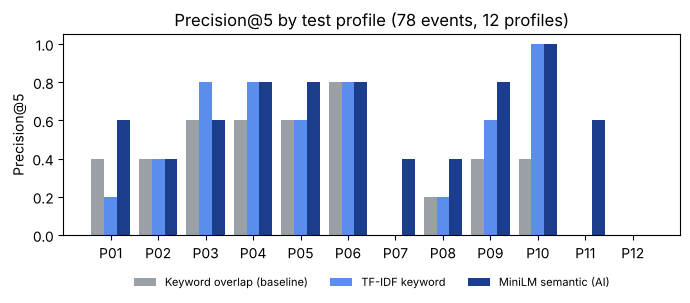

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(profiles)); w = 0.27
colors = ['#9aa0a6', '#5b8def', '#1a3e8c']
for i, name in enumerate(METHODS):
    vals = results[results.method == name].set_index('profile_id').loc[profiles.profile_id, 'precision@5']
    ax.bar(x + (i - 1) * w, vals, w, label=name, color=colors[i])
ax.set_xticks(x); ax.set_xticklabels(profiles.profile_id); ax.set_ylim(0, 1.05)
ax.set_ylabel('Precision@5'); ax.set_title('Precision@5 by test profile (78 events, 12 profiles)')
ax.legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout(); plt.savefig('results_precision_by_profile.png', dpi=200); plt.show()

## 7. Example output

In [10]:
def show(profile_id, method):
    p = profiles.set_index('profile_id').loc[profile_id]
    ids, sc = top_k(METHODS[method](p['profile_text']))
    out = events.set_index('event_id').loc[ids, ['title', 'category']].copy()
    out.insert(0, 'rank', range(1, K + 1)); out['score'] = np.round(sc, 3)
    out['relevant'] = ['yes' if i in p['relevant'] else 'no' for i in ids]
    print(f"{profile_id}: {p['profile_text']}\nMethod: {method}")
    return out

show('P07', 'MiniLM semantic (AI)')

P07: I want to be a doctor or work in healthcare someday.
Method: MiniLM semantic (AI)


,rank,title,category,score,relevant
event_id,,,,,
E38,1,Fall 2026 Career Fair,Career and Professional,0.440,no
E09,2,4th Annual Divine Nine Project Access Event,Health,0.327,yes
E15,3,N.C. A&T Physician Assistant Studies Virtual Open House,Health,0.298,yes
E52,4,Faculty/Staff Institute 2026,Faculty and Staff,0.270,no
E23,5,2026 N.C. A&T Honors College Research Conference,Research and Library,0.268,no


In [11]:
show('P07', 'Keyword overlap (baseline)')

P07: I want to be a doctor or work in healthcare someday.
Method: Keyword overlap (baseline)


,rank,title,category,score,relevant
event_id,,,,,
E31,1,COAACH Lunch and Learn: Questions to Ask Your Doctor,Health,1.0,no
E01,2,Auditions: E. Gwynn Dancers of N.C. A&T,Arts and Performance,0.0,no
E02,3,Research Impact: Assessing and Tracking Your Research,Research and Library,0.0,no
E03,4,Navigating the Open Access Landscape,Research and Library,0.0,no
E04,5,Unlocking Your Publishing Potential,Research and Library,0.0,no


## 8. Weak cases

In [12]:
show('P01', 'MiniLM semantic (AI)')

P01: I'm a computer science major and I want to learn about new tech like AI, robotics and quantum computing.
Method: MiniLM semantic (AI)


,rank,title,category,score,relevant
event_id,,,,,
E27,1,"Code It, Watch It Go: Edison Robotics Fun",Technology and Engineering,0.441,no
E29,2,Faculty Technical Speaker Series: Quantum Computing,Technology and Engineering,0.386,yes
E28,3,College of Education Aggies Innovate Expo: Driving Innovation,Technology and Engineering,0.290,yes
E20,4,2026 Provost's Faculty Fellows Poster Presentations,Technology and Engineering,0.285,yes
E52,5,Faculty/Staff Institute 2026,Faculty and Staff,0.261,no


In [13]:
show('P02', 'MiniLM semantic (AI)')

P02: I need a job or internship and want to meet employers and work on my professional skills.
Method: MiniLM semantic (AI)


,rank,title,category,score,relevant
event_id,,,,,
E38,1,Fall 2026 Career Fair,Career and Professional,0.474,yes
E09,2,4th Annual Divine Nine Project Access Event,Health,0.315,no
E15,3,N.C. A&T Physician Assistant Studies Virtual Open House,Health,0.290,no
E07,4,Study Abroad Information Session (In Person),Global and International,0.280,no
E22,5,Aggie Pathways Abroad: From North Carolina to the UK,Global and International,0.260,yes


In [14]:
show('P12', 'MiniLM semantic (AI)')

P12: I like running, working out and staying healthy.
Method: MiniLM semantic (AI)


,rank,title,category,score,relevant
event_id,,,,,
E13,1,Make the Most of Your Benefits: Resources Support Your Success,Faculty and Staff,0.238,no
E01,2,Auditions: E. Gwynn Dancers of N.C. A&T,Arts and Performance,0.142,no
E38,3,Fall 2026 Career Fair,Career and Professional,0.123,no
E62,4,Aggie Volleyball vs. Wake Forest University,Sports and Fitness,0.120,no
E76,5,Homecoming Parade,Homecoming and Student Life,0.112,no


## 9. What these tests do and do not show
The numbers above come from 12 profiles and 78 events, with relevance labeled by one person. That is enough to see whether the pipeline works and which method tends to find more relevant events, but it is too small to claim one method is better in general. Not yet completed: a second labeler, more test profiles, real 1891Connect student organization events, and the Gradio interface.